In [ ]:
# Simulator from https://github.com/harshitasingh4863/instruction-level-parallelism-simulator.git

from dataclasses import dataclass


@dataclass
class Instruction:
    name: str
    destination: str
    sources: list


# -------------------------------------------------
# Sample Instruction Set
# -------------------------------------------------

instructions = [
    Instruction("I1", "R1", ["R2", "R3"]),
    Instruction("I2", "R4", ["R5", "R6"]),
    Instruction("I3", "R7", ["R1", "R4"]),
    Instruction("I4", "R8", ["R9", "R10"]),
    Instruction("I5", "R11", ["R7", "R8"]),
    Instruction("I6", "R12", ["R13", "R14"]),
]


# -------------------------------------------------
# Function to check dependency
# -------------------------------------------------

def has_dependency(inst1, inst2):
    """
    Returns True if inst2 depends on inst1.
    """

    # RAW dependency:
    # inst2 reads a register written by inst1
    if inst1.destination in inst2.sources:
        return True

    return False


# -------------------------------------------------
# Sequential Execution
# -------------------------------------------------

def sequential_execution(instructions):
    print("\n" + "=" * 50)
    print("SEQUENTIAL EXECUTION")
    print("=" * 50)

    cycle = 0

    for instruction in instructions:
        cycle += 1

        print(
            f"Cycle {cycle}: Executing {instruction.name} "
            f"({instruction.destination} = "
            f"{' + '.join(instruction.sources)})"
        )

    print(f"\nTotal Sequential Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# ILP / Parallel Execution
# -------------------------------------------------

def parallel_execution(instructions):
    print("\n" + "=" * 50)
    print("INSTRUCTION-LEVEL PARALLEL EXECUTION")
    print("=" * 50)

    completed = set()
    remaining = instructions.copy()

    cycle = 0

    while remaining:

        cycle += 1
        current_cycle = []

        for instruction in remaining:

            # Check whether all previous dependencies
            # have already been completed

            dependencies_satisfied = True

            for previous in instructions:

                if previous.name == instruction.name:
                    break

                if has_dependency(previous, instruction):
                    if previous.name not in completed:
                        dependencies_satisfied = False
                        break

            if dependencies_satisfied:
                current_cycle.append(instruction)

        # Execute all independent instructions
        # in the same cycle

        print(f"\nCycle {cycle}:")

        for instruction in current_cycle:
            print(
                f"  -> {instruction.name}: "
                f"{instruction.destination} = "
                f"{' + '.join(instruction.sources)}"
            )

        # Mark instructions as completed

        for instruction in current_cycle:
            completed.add(instruction.name)
            remaining.remove(instruction)

    print(f"\nTotal ILP Cycles: {cycle}")

    return cycle


# -------------------------------------------------
# Dependency Analysis
# -------------------------------------------------

def show_dependencies(instructions):

    print("\n" + "=" * 50)
    print("DEPENDENCY ANALYSIS")
    print("=" * 50)

    found = False

    for i in range(len(instructions)):

        for j in range(i + 1, len(instructions)):

            if has_dependency(instructions[i], instructions[j]):

                print(
                    f"{instructions[j].name} depends on "
                    f"{instructions[i].name} "
                    f"(Register: {instructions[i].destination})"
                )

                found = True

    if not found:
        print("No dependencies found.")


# -------------------------------------------------
# Main Program
# -------------------------------------------------

def main():

    print("\n")
    print("*" * 60)
    print("      INSTRUCTION-LEVEL PARALLELISM SIMULATOR")
    print("*" * 60)

    print("\nInstruction Set:")

    for instruction in instructions:
        print(
            f"{instruction.name}: "
            f"{instruction.destination} = "
            f"{' + '.join(instruction.sources)}"
        )

    # Show dependencies

    show_dependencies(instructions)

    # Sequential execution

    sequential_cycles = sequential_execution(instructions)

    # Parallel execution

    parallel_cycles = parallel_execution(instructions)

    # Calculate speedup

    speedup = sequential_cycles / parallel_cycles

    efficiency = speedup / len(instructions) * 100

    print("\n" + "=" * 50)
    print("PERFORMANCE COMPARISON")
    print("=" * 50)

    print(f"Sequential Cycles : {sequential_cycles}")
    print(f"ILP Cycles        : {parallel_cycles}")
    print(f"Speedup            : {speedup:.2f}x")
    print(f"ILP Efficiency     : {efficiency:.2f}%")

    print("\nConclusion:")
    print(
        "ILP reduces execution cycles by allowing "
        "independent instructions to execute in parallel."
    )


# -------------------------------------------------
# Run Program
# -------------------------------------------------

if __name__ == "__main__":
    main()




************************************************************
      INSTRUCTION-LEVEL PARALLELISM SIMULATOR
************************************************************

Instruction Set:
I1: R1 = R2 + R3
I2: R4 = R5 + R6
I3: R7 = R1 + R4
I4: R8 = R9 + R10
I5: R11 = R7 + R8
I6: R12 = R13 + R14

DEPENDENCY ANALYSIS
I3 depends on I1 (Register: R1)
I3 depends on I2 (Register: R4)
I5 depends on I3 (Register: R7)
I5 depends on I4 (Register: R8)

SEQUENTIAL EXECUTION
Cycle 1: Executing I1 (R1 = R2 + R3)
Cycle 2: Executing I2 (R4 = R5 + R6)
Cycle 3: Executing I3 (R7 = R1 + R4)
Cycle 4: Executing I4 (R8 = R9 + R10)
Cycle 5: Executing I5 (R11 = R7 + R8)
Cycle 6: Executing I6 (R12 = R13 + R14)

Total Sequential Cycles: 6

INSTRUCTION-LEVEL PARALLEL EXECUTION

Cycle 1:
  -> I1: R1 = R2 + R3
  -> I2: R4 = R5 + R6
  -> I4: R8 = R9 + R10
  -> I6: R12 = R13 + R14

Cycle 2:
  -> I3: R7 = R1 + R4

Cycle 3:
  -> I5: R11 = R7 + R8

Total ILP Cycles: 3

PERFORMANCE COMPARISON
Sequential Cycles : 6
ILP Cyc

DEPENDENCY ANALYSIS - RAW
I1 -> I2 (RAW R1)
I2 -> I3 (RAW R5)


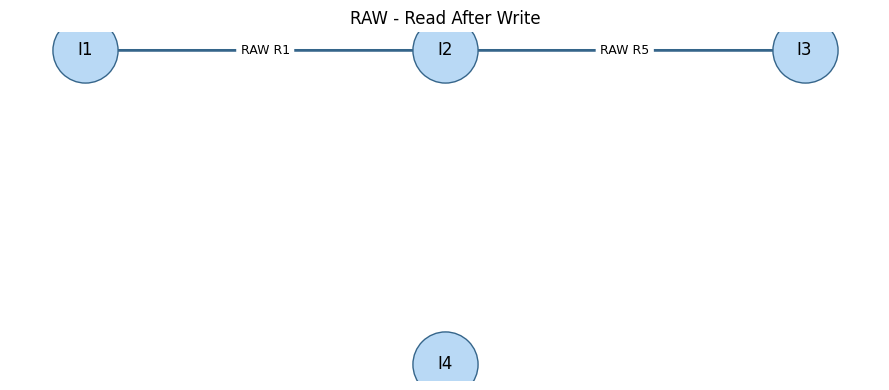

In [7]:

import matplotlib.pyplot as plt
import networkx as nx

# Contoh instruksi RAW
instruksi = {
    "I1": {"baca": ["R2", "R3"], "tulis": ["R1"]},
    "I2": {"baca": ["R1", "R4"], "tulis": ["R5"]},
    "I3": {"baca": ["R5", "R6"], "tulis": ["R7"]},
    "I4": {"baca": ["R8", "R9"], "tulis": ["R10"]}
}

G = nx.DiGraph()
G.add_nodes_from(instruksi)

for i, data_i in instruksi.items():
    for j, data_j in instruksi.items():
        if list(instruksi).index(i) < list(instruksi).index(j):
            reg = set(data_i["tulis"]) & set(data_j["baca"])
            if reg:
                G.add_edge(i, j, label="RAW " + ", ".join(sorted(reg)))

print("DEPENDENCY ANALYSIS - RAW")
for u, v, data in G.edges(data=True):
    print(f"{u} -> {v} ({data['label']})")

pos = {"I1": (0, 1), "I2": (2, 1),
       "I3": (4, 1), "I4": (2, -1)}

plt.figure(figsize=(9, 4))
nx.draw_networkx_nodes(G, pos, node_color="#B9D9F5",
                       node_size=2200, edgecolors="#35658A")
nx.draw_networkx_labels(G, pos, font_size=12)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=22,
                       width=2, edge_color="#35658A")
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=9, label_pos=0.5
)
plt.title("RAW - Read After Write")
plt.axis("off")
plt.tight_layout()
plt.show()


DEPENDENCY ANALYSIS - WAR
I1 -> I2 (WAR R1)
I1 -> I3 (WAR R2)


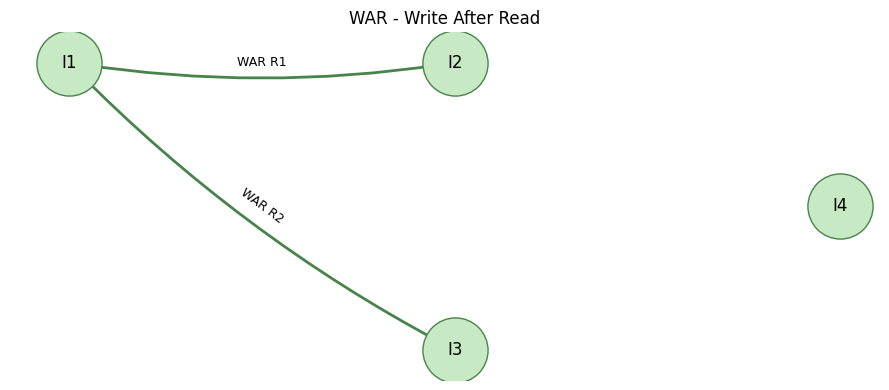

In [8]:

import matplotlib.pyplot as plt
import networkx as nx

# Contoh instruksi WAR
instruksi = {
    "I1": {"baca": ["R1", "R2"], "tulis": ["R3"]},
    "I2": {"baca": ["R4"], "tulis": ["R1"]},
    "I3": {"baca": ["R3"], "tulis": ["R2"]},
    "I4": {"baca": ["R5"], "tulis": ["R6"]}
}

G = nx.DiGraph()
G.add_nodes_from(instruksi)

for i, data_i in instruksi.items():
    for j, data_j in instruksi.items():
        if list(instruksi).index(i) < list(instruksi).index(j):
            reg = set(data_i["baca"]) & set(data_j["tulis"])
            if reg:
                G.add_edge(i, j, label="WAR " + ", ".join(sorted(reg)))

print("DEPENDENCY ANALYSIS - WAR")
for u, v, data in G.edges(data=True):
    print(f"{u} -> {v} ({data['label']})")

pos = {"I1": (0, 1), "I2": (2, 1),
       "I3": (2, -1), "I4": (4, 0)}

plt.figure(figsize=(9, 4))
nx.draw_networkx_nodes(G, pos, node_color="#C7EAC5",
                       node_size=2200, edgecolors="#47834A")
nx.draw_networkx_labels(G, pos, font_size=12)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=22,
                       width=2, edge_color="#47834A",
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=9, label_pos=0.5
)
plt.title("WAR - Write After Read")
plt.axis("off")
plt.tight_layout()
plt.show()


DEPENDENCY ANALYSIS - WAW
I1 -> I2 (WAW R1)
I1 -> I3 (WAW R1)
I2 -> I3 (WAW R1)


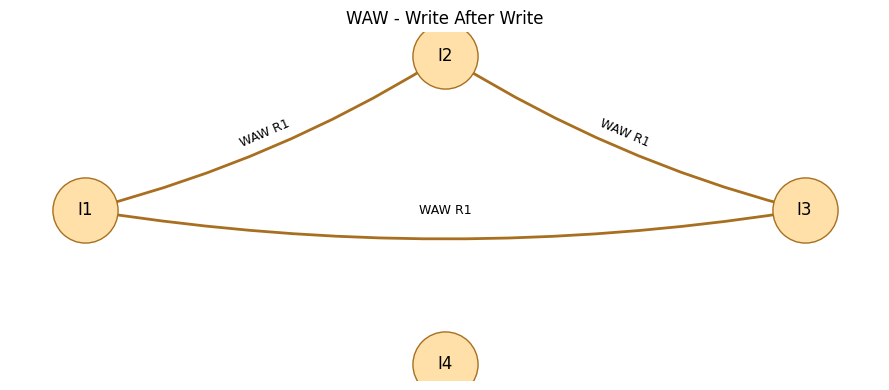

In [9]:

import matplotlib.pyplot as plt
import networkx as nx

# Contoh instruksi WAW
instruksi = {
    "I1": {"baca": ["R2"], "tulis": ["R1"]},
    "I2": {"baca": ["R3"], "tulis": ["R1"]},
    "I3": {"baca": ["R4"], "tulis": ["R1"]},
    "I4": {"baca": ["R5"], "tulis": ["R6"]}
}

G = nx.DiGraph()
G.add_nodes_from(instruksi)

for i, data_i in instruksi.items():
    for j, data_j in instruksi.items():
        if list(instruksi).index(i) < list(instruksi).index(j):
            reg = set(data_i["tulis"]) & set(data_j["tulis"])
            if reg:
                G.add_edge(i, j, label="WAW " + ", ".join(sorted(reg)))

print("DEPENDENCY ANALYSIS - WAW")
for u, v, data in G.edges(data=True):
    print(f"{u} -> {v} ({data['label']})")

pos = {"I1": (0, 0), "I2": (2, 1),
       "I3": (4, 0), "I4": (2, -1)}

plt.figure(figsize=(9, 4))
nx.draw_networkx_nodes(G, pos, node_color="#FFE0A8",
                       node_size=2200, edgecolors="#A86F20")
nx.draw_networkx_labels(G, pos, font_size=12)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=22,
                       width=2, edge_color="#A86F20",
                       connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=nx.get_edge_attributes(G, "label"),
    font_size=9, label_pos=0.5
)
plt.title("WAW - Write After Write")
plt.axis("off")
plt.tight_layout()
plt.show()
